In [26]:
import pandas as pd
import numpy as np
import xarray as xr

import matplotlib.pyplot as plt

from xgboost import XGBRegressor
from sklearn.model_selection import GroupKFold

#### Load and Prepare Data

In [27]:
point = 'p102'
data_pcs = pd.read_csv("outputs/pca/pcs_msl_sel_6h.csv", index_col=0, parse_dates=True)
waves_df_z = pd.read_csv(f"outputs/marginal/z_bulk_{point}.csv", index_col=0, parse_dates=True)   # PIT + armónica (00_PIT)
horas_6h = [0, 6, 12, 18]
waves_df_z_6h = waves_df_z.rolling("6h", center=True).mean()
waves_df_z_6h = waves_df_z_6h[waves_df_z_6h.index.hour.isin(horas_6h)].dropna()

In [28]:
lags = [0, 6, 12, 18, 24, 30, 36]
pcs_msl_lagged = pd.concat({f"l{l}": data_pcs.shift(freq=pd.Timedelta(hours=l)) for l in lags}, axis=1).reindex(data_pcs.index)
pcs_msl_lagged.columns = [f"{c}_l{l[1:]}" for l, c in pcs_msl_lagged.columns]
pcs_msl_lagged = pcs_msl_lagged.dropna()

idx = pcs_msl_lagged.index.intersection(waves_df_z_6h.index)
X = pcs_msl_lagged.loc[idx]
y = waves_df_z_6h.loc[idx, 'VHM0']

#### CrossValidation

In [29]:
tr = idx < "2016-01-01"
X_tr, y_tr = X[tr], y[tr]

In [30]:
f_oof = pd.Series(np.nan, index=X_tr.index)
for i_fit, i_val in GroupKFold(n_splits=6).split(X_tr, y_tr, groups=X_tr.index.year):
    xgboost_model = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, min_child_weight=200, 
                             subsample=0.8, colsample_bytree=0.8,
                       tree_method="hist", n_jobs=-1, random_state=0
    )
    xgboost_model.fit(X_tr.iloc[i_fit], y_tr.iloc[i_fit])
    f_oof.iloc[i_val] = xgboost_model.predict(X_tr.iloc[i_val])


#### Full model

In [31]:
xgb_final = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, min_child_weight=200,
                         subsample=0.8, colsample_bytree=0.8, tree_method="hist", n_jobs=-1, random_state=0)
xgb_final.fit(X_tr, y_tr)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [32]:
y_predict = xgb_final.predict(X)
y_predict = pd.DataFrame(y_predict)
y_predict.index = waves_df_z_6h.index

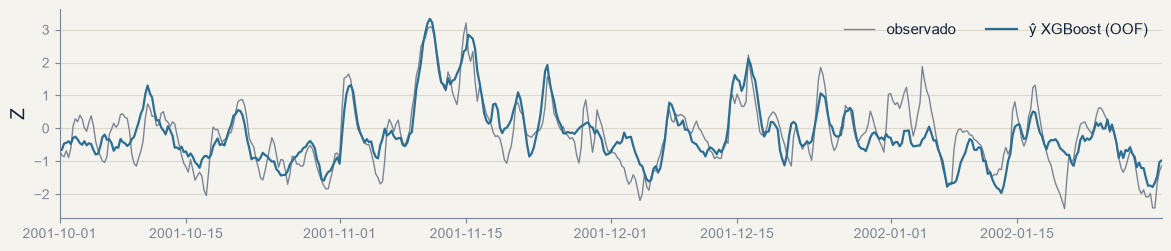

In [41]:
#### Estilo presentación
TINTA, AZUL, NARANJA, GRIS, FONDO = "#13233A", "#2C6E91", "#C8622A", "#7A8594", "#F5F3EE"
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Inter", "Arial", "DejaVu Sans"],
    "font.size": 14, "axes.titlesize": 17, "axes.labelsize": 14,
    "xtick.labelsize": 12, "ytick.labelsize": 12,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA, "text.color": TINTA,
    "xtick.color": GRIS, "ytick.color": GRIS,
})

t0, t1 = "2001-10-01", "2002-01-31"

fig, ax = plt.subplots(figsize=(11.6, 2.4), constrained_layout=True, facecolor=FONDO)
ax.plot(y.loc[t0:t1], color=GRIS, lw=1, label="observado")
ax.plot(f_oof.loc[t0:t1], color=AZUL, lw=1.6, label="ŷ XGBoost (OOF)")
ax.axhline(0, color="#DDD8CE", lw=0.8, zorder=0)
ax.set(ylabel="Z", xlim=(pd.Timestamp(t0), pd.Timestamp(t1)))
ax.set_facecolor(FONDO)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#DDD8CE", lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(labelsize=10)
ax.legend(frameon=False, loc="upper right", ncol=2, fontsize=11)

fig.savefig("figuras/xgb_serie_invierno.png", dpi=200, facecolor=FONDO)
plt.show()

In [34]:
print(f"6-horaria: {y_predict[0].corr(y):.3f}")
print(f"6-horaria oof: {f_oof.corr(y):.3f}")
print(f"diaria:    {y_predict[0].resample('D').mean().corr(y.resample('D').mean()):.3f}")
print(f"diaria:    {f_oof.resample('D').mean().corr(y.resample('D').mean()):.3f}")

6-horaria: 0.851
6-horaria oof: 0.785
diaria:    0.876
diaria:    0.818


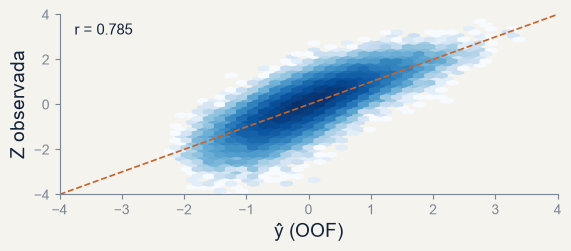

In [42]:
d = pd.concat({"z": y, "f": f_oof}, axis=1).dropna()

fig, ax = plt.subplots(figsize=(5.6, 2.4), constrained_layout=True, facecolor=FONDO)
hb = ax.hexbin(d["f"], d["z"], gridsize=45, cmap="Blues", mincnt=1, bins="log", extent=(-4, 4, -4, 4))
ax.plot([-4, 4], [-4, 4], color=NARANJA, lw=1.2, ls="--")
ax.text(0.03, 0.95, f"r = {d['z'].corr(d['f']):.3f}", transform=ax.transAxes, va="top", fontsize=11)
ax.set(xlabel="ŷ (OOF)", ylabel="Z observada", xlim=(-4, 4), ylim=(-4, 4))
ax.set_facecolor(FONDO)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(labelsize=10)

fig.savefig("figuras/xgb_dispersion.png", dpi=200, facecolor=FONDO)
plt.show()

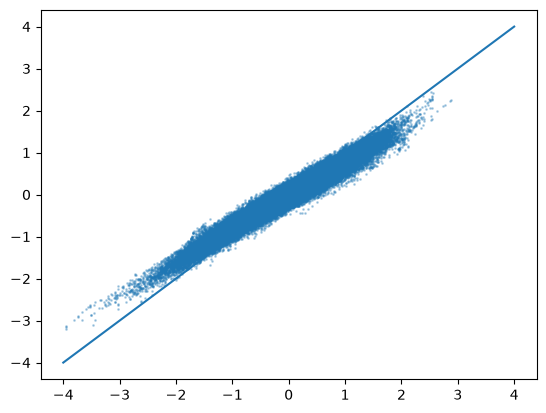

In [35]:
f_h_oof = f_oof.resample('h').interpolate()
r_h_off = (waves_df_z['VHM0'] - f_h_oof).dropna()

f_in = pd.Series(xgb_final.predict(X_tr), index=X_tr.index)
r_h_in = (waves_df_z['VHM0'] - f_in.resample('h').interpolate()).dropna()

r = pd.concat({"oof": r_h_off, "in": r_h_in}, axis=1).dropna()
plt.scatter(r["oof"], r["in"], s=1, alpha=0.3)
plt.plot([-4,4],[-4,4])

In [36]:
print(r.std(), np.polyfit(r["oof"], r["in"], 1)[0])

oof    0.627432
in     0.507172
dtype: float64 0.7875795862265481


In [37]:
import os, json
os.makedirs(f"outputs/xgb_pit_{point}", exist_ok=True)

#### Modelo final + orden de columnas que espera
xgb_final.save_model(f"outputs/xgb_pit_{point}/xgb_final.json")
with open(f"outputs/xgb_pit_{point}/xgb_features.json", "w") as f:
    json.dump({"columns": list(X_tr.columns), "lags_h": lags, "train": ["1985-01-01", "2015-12-31"]}, f, indent=1)

#### Serie horaria: z, f y residuo (OOF en 1985–2015, modelo final en 2016–2025)
f_6h = pd.concat([f_oof, pd.Series(xgb_final.predict(X[~tr]), index=X.index[~tr])]).sort_index()
f_h = f_6h.resample("h").interpolate()
z_h = waves_df_z['VHM0'].reindex(f_h.index)

residuos = pd.DataFrame({"z": z_h, "f": f_h, "r": z_h - f_h})
residuos["periodo"] = np.where(residuos.index < "2016-01-01", "oof", "test")
residuos.dropna(subset=["r"]).to_csv(f"outputs/xgb_pit_{point}/residuos_horarios.csv")
print(residuos.dropna().groupby("periodo")["r"].agg(["count", "std"]))

          count       std
periodo                  
oof      271728  0.627427
test      94219  0.619200


#### TEST — ¿Cuántos retardos? Mismo XGB con distintos lags, evaluado en los picos de f

In [38]:
from scipy.signal import find_peaks

conjuntos = {"0–12": [0, 6, 12], "0–18": [0, 6, 12, 18], "0–24": [0, 6, 12, 18, 24],
             "0–36": [0, 6, 12, 18, 24, 30, 36], "0–48": [0, 6, 12, 18, 24, 30, 36, 42, 48]}
params = dict(n_estimators=300, learning_rate=0.05, max_depth=6, min_child_weight=200,
              subsample=0.8, colsample_bytree=0.8, tree_method="hist", n_jobs=-1, random_state=0)
z_hor = waves_df_z["VHM0"]
ventana = np.arange(-48, 49)

def metricas_picos(f_h, z_h, q=0.99):
    """Z observado alrededor de los máximos locales de f (> q): ¿f se pasa? ¿llega tarde?"""
    pk, _ = find_peaks(f_h.values, height=f_h.quantile(q), distance=72)
    pk = pk[(pk > 48) & (pk < len(f_h) - 49)]
    comp_z = np.nanmean([z_h.values[i + ventana] for i in pk], axis=0)
    comp_f = np.nanmean([f_h.values[i + ventana] for i in pk], axis=0)
    return {"n picos": len(pk),
            "r en pico": np.nanmean(z_h.values[pk] - f_h.values[pk]),            # <0: f se pasa en su pico
            "Δ pico compuesto": comp_z.max() - comp_f.max(),                      # <0: el pico medio de f es más alto
            "desfase h": ventana[np.argmax(comp_z)],                              # <0: Z observado pica antes que f
            "exceso máx ±24h": np.nanmean([np.nanmax(z_h.values[i - 24:i + 25]) - f_h.values[i] for i in pk])}, comp_z - comp_f

filas, sesgo = [], {}
for nombre, lags_k in conjuntos.items():
    #### Mismos pasos que arriba, con otro conjunto de lags
    X_k = pd.concat({f"l{l}": data_pcs.shift(freq=pd.Timedelta(hours=l)) for l in lags_k}, axis=1).reindex(data_pcs.index)
    X_k.columns = [f"{c}_l{l[1:]}" for l, c in X_k.columns]
    X_k = X_k.dropna()
    idx_k = X_k.index.intersection(waves_df_z_6h.index)
    X_k, y_k = X_k.loc[idx_k], waves_df_z_6h.loc[idx_k, "VHM0"]
    tr_k = idx_k < "2016-01-01"

    f_oof_k = pd.Series(np.nan, index=X_k.index[tr_k])
    for i_fit, i_val in GroupKFold(n_splits=6).split(X_k[tr_k], y_k[tr_k], groups=X_k.index[tr_k].year):
        m_k = XGBRegressor(**params).fit(X_k[tr_k].iloc[i_fit], y_k[tr_k].iloc[i_fit])
        f_oof_k.iloc[i_val] = m_k.predict(X_k[tr_k].iloc[i_val])
    m_k = XGBRegressor(**params).fit(X_k[tr_k], y_k[tr_k])

    f_6h_k = pd.concat([f_oof_k, pd.Series(m_k.predict(X_k[~tr_k]), index=X_k.index[~tr_k])]).sort_index()
    f_h_k = f_6h_k.resample("h").interpolate()
    z_h_k = z_hor.reindex(f_h_k.index)

    for per, (a, b) in {"oof": ("1985", "2015"), "test": ("2016", "2025")}.items():
        fila = {"periodo": per, "lags": nombre,
                "corr 6h": f_6h_k.loc[a:b].corr(y_k.loc[a:b]), "corr h": f_h_k.loc[a:b].corr(z_h_k.loc[a:b])}
        m_pk, sesgo[(per, nombre)] = metricas_picos(f_h_k.loc[a:b], z_h_k.loc[a:b])
        fila.update(m_pk)
        filas.append(fila)
    print(nombre, "ok")

tabla_lags = pd.DataFrame(filas).set_index(["periodo", "lags"])
print(tabla_lags.round(3).to_string())

0–12 ok
0–18 ok
0–24 ok
0–36 ok
0–48 ok
              corr 6h  corr h  n picos  r en pico  Δ pico compuesto  desfase h  exceso máx ±24h
periodo lags                                                                                   
oof     0–12    0.768   0.764      139     -0.240            -0.209         -2            0.126
test    0–12    0.763   0.757       45     -0.216            -0.216          0            0.083
oof     0–18    0.780   0.776      145     -0.165            -0.136         -3            0.179
test    0–18    0.773   0.768       46     -0.221            -0.221          0            0.108
oof     0–24    0.783   0.780      136     -0.164            -0.131         -3            0.208
test    0–24    0.778   0.772       44     -0.200            -0.200          0            0.114
oof     0–36    0.785   0.781      142     -0.146            -0.127         -2            0.198
test    0–36    0.779   0.773       44     -0.215            -0.215          0            0.131


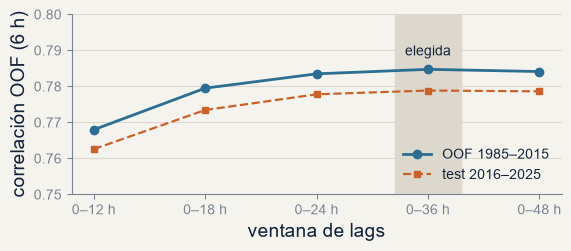

In [43]:
#### Sensibilidad a la ventana de lags (de tabla_lags)
t = tabla_lags["corr 6h"].unstack("periodo").loc[list(conjuntos)]

fig, ax = plt.subplots(figsize=(5.6, 2.4), constrained_layout=True, facecolor=FONDO)
x = np.arange(len(t))
ax.plot(x, t["oof"], "o-", color=AZUL, lw=2, ms=6, label="OOF 1985–2015")
ax.plot(x, t["test"], "s--", color=NARANJA, lw=1.6, ms=5, label="test 2016–2025")

#### Ventana elegida
i_sel = list(t.index).index("0–36")
ax.axvspan(i_sel - 0.3, i_sel + 0.3, color="#DDD8CE", zorder=0)
ax.annotate("elegida", (i_sel, t["oof"].iloc[i_sel]), xytext=(0, 10), textcoords="offset points",
            ha="center", fontsize=10, color=TINTA)

ax.set_xticks(x, [f"{n} h" for n in t.index])
ax.set(xlabel="ventana de lags", ylabel="correlación OOF (6 h)", ylim=(0.75, 0.80))
ax.set_facecolor(FONDO)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#DDD8CE", lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(labelsize=10)
ax.legend(frameon=False, fontsize=10, loc="lower right")

fig.savefig("figuras/xgb_lags.png", dpi=200, facecolor=FONDO)
plt.show()

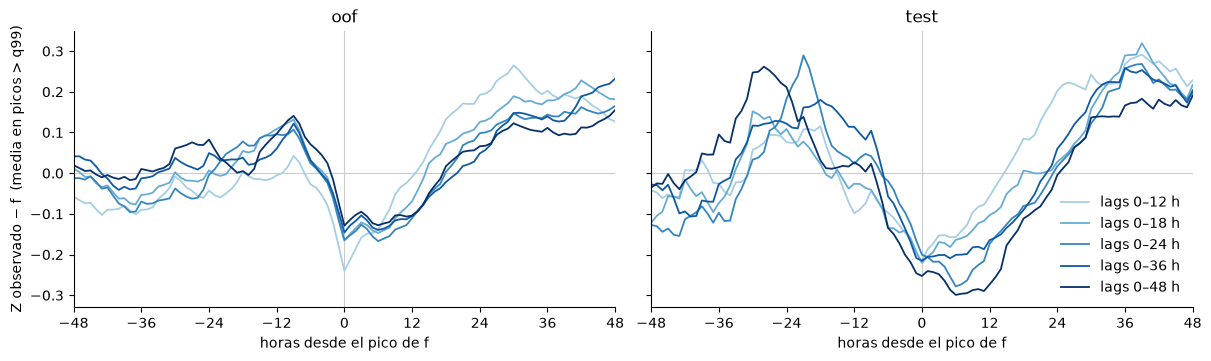

In [39]:
#### Sesgo medio de f alrededor de sus picos (Z observado − f): 0 = f perfecta en tormenta
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True, constrained_layout=True)
cmap = plt.cm.Blues
for ax, per in zip(axs, ["oof", "test"]):
    for j, nombre in enumerate(conjuntos):
        ax.plot(ventana, sesgo[(per, nombre)], color=cmap(0.35 + 0.65 * j / (len(conjuntos) - 1)), lw=1.3, label=f"lags {nombre} h")
    ax.axhline(0, color="0.8", lw=0.8, zorder=0)
    ax.axvline(0, color="0.8", lw=0.8, zorder=0)
    ax.set(title=per, xlabel="horas desde el pico de f", xticks=np.arange(-48, 49, 12), xlim=(-48, 48))
    ax.spines[["top", "right"]].set_visible(False)
axs[0].set_ylabel("Z observado − f  (media en picos > q99)")
axs[1].legend(frameon=False, loc="lower right")
plt.show()